# Uczenie maszynowe 1
## Pracownia specjalistyczna nr 3
### Wstępne przetwarzanie danych II: transformacja, skalowanie i współliniowość

Zbiór `klienci_sklepu_dydaktyczne.csv` jest sztucznym zbiorem przygotowanym wyłącznie do celów dydaktycznych.

## Cele zajęć

Po zajęciach student powinien potrafić:
- ocenić normalność rozkładu testem i wykresem Q-Q,
- obliczyć i zinterpretować skośność,
- zastosować transformację logarytmiczną,
- sprawdzić jednorodność wariancji testem Levene’a/Browna-Forsythe’a,
- zastosować One-Hot Encoding,
- rozróżnić `MinMaxScaler`, `StandardScaler`, `RobustScaler` i `Normalizer`,
- dopasować skaler wyłącznie na treningu,
- ocenić współliniowość za pomocą korelacji i VIF.

## 1. Import bibliotek

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import shapiro, levene
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler, RobustScaler, Normalizer
from sklearn.linear_model import LinearRegression

## 2. Odczyt danych

In [4]:
df = pd.read_csv('klienci_sklepu_dydaktyczne.csv')
df.head()

,id,kanal,region,staz_mies,wizyty_mies,czas_realizacji_min,wydatki_mies_pln,wydatki_roczne_pln,satysfakcja,liczba_produktow
0,1,WWW,Zachód,35,7,16.24,297.55,3455.51,7.32,2
1,2,Aplikacja,Wschód,52,6,24.16,345.89,4132.63,7.70,5
2,3,Aplikacja,Zachód,13,12,15.01,349.68,3847.25,8.96,3
3,4,WWW,Zachód,52,8,19.18,272.66,3524.04,5.36,4
4,5,WWW,Wschód,17,5,13.45,300.19,3617.08,4.06,2


In [5]:
print('Rozmiar:', df.shape)
df.info()

Rozmiar: (120, 10)
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   120 non-null    int64  
 1   kanal                120 non-null    str    
 2   region               120 non-null    str    
 3   staz_mies            120 non-null    int64  
 4   wizyty_mies          120 non-null    int64  
 5   czas_realizacji_min  120 non-null    float64
 6   wydatki_mies_pln     120 non-null    float64
 7   wydatki_roczne_pln   120 non-null    float64
 8   satysfakcja          120 non-null    float64
 9   liczba_produktow     120 non-null    int64  
dtypes: float64(4), int64(4), str(2)
memory usage: 9.5 KB


In [6]:
df.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
id,120.0,60.500000,34.785054,1.00,30.7500,60.500,90.2500,120.00
staz_mies,120.0,36.525000,19.265052,1.00,20.7500,36.500,52.0000,72.00
wizyty_mies,120.0,8.708333,2.914455,2.00,6.7500,9.000,11.0000,16.00
czas_realizacji_min,120.0,18.021583,3.823955,9.98,15.5075,17.960,19.9025,29.14
wydatki_mies_pln,120.0,534.144583,399.654034,76.71,269.8300,390.795,737.3525,2246.42
wydatki_roczne_pln,120.0,6383.029750,4827.298553,302.10,3214.5050,4859.990,8735.2350,26972.90
satysfakcja,120.0,7.009083,1.161929,4.06,6.2300,7.105,7.7225,9.93
liczba_produktow,120.0,3.516667,1.978809,1.00,2.0000,3.000,5.0000,12.00


# Część A. Rozkład danych i transformacje

## 3. Normalność rozkładu

Sprawdzimy `satysfakcja`.

- H₀: dane są zgodne z rozkładem normalnym,
- H₁: dane nie są zgodne z rozkładem normalnym.

Dla α=0,05: `p<0.05` oznacza odrzucenie H₀. Wynik testu analizujemy razem z histogramem i wykresem Q-Q.

In [7]:
x = df['satysfakcja']
stat, p = shapiro(x)
print(f'Shapiro-Wilk: stat={stat:.4f}, p={p:.4f}')
print('Odrzucamy H0.' if p < 0.05 else 'Brak podstaw do odrzucenia H0.')

Shapiro-Wilk: stat=0.9958, p=0.9800
Brak podstaw do odrzucenia H0.


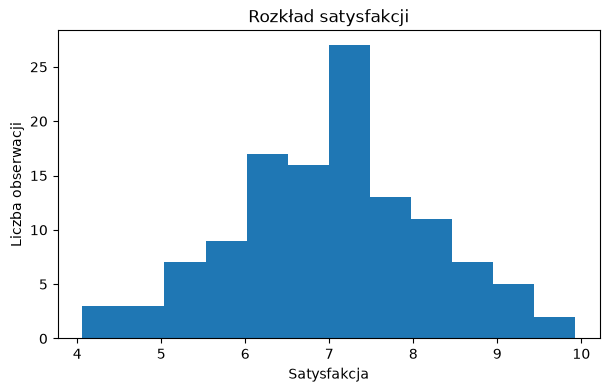

In [8]:
plt.figure(figsize=(7,4))
plt.hist(x, bins=12)
plt.xlabel('Satysfakcja'); plt.ylabel('Liczba obserwacji'); plt.title('Rozkład satysfakcji')
plt.show()

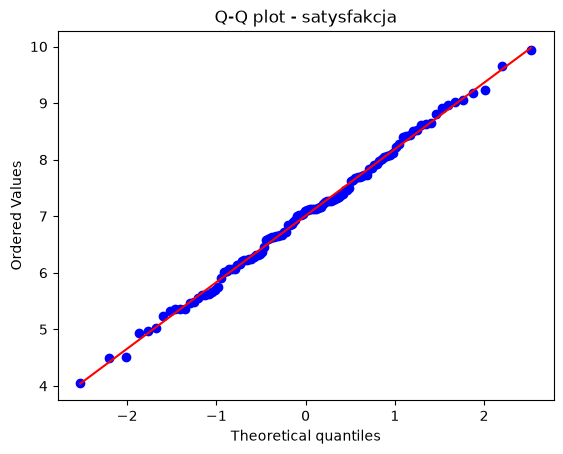

In [9]:
stats.probplot(x, dist='norm', plot=plt)
plt.title('Q-Q plot - satysfakcja')
plt.show()

Punkty na Q-Q plot blisko prostej wspierają zgodność z rozkładem normalnym. Systematyczne wygięcie lub odchylenia w ogonach wskazują na rozbieżności.

## 4. Skośność rozkładu

Skośność: 1.956


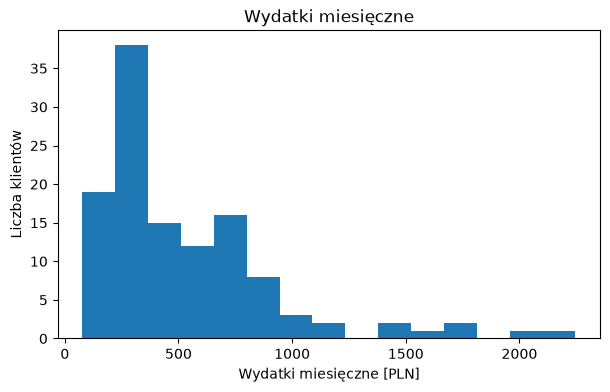

In [10]:
spending = df['wydatki_mies_pln']
print('Skośność:', round(spending.skew(),3))
plt.figure(figsize=(7,4))
plt.hist(spending, bins=15)
plt.xlabel('Wydatki miesięczne [PLN]'); plt.ylabel('Liczba klientów'); plt.title('Wydatki miesięczne')
plt.show()

Dodatnia skośność oznacza wydłużony prawy ogon, ujemna — lewy. Im większa wartość bezwzględna współczynnika, tym silniejsza asymetria.

## 5. Transformacja logarytmiczna

Dla dodatniej zmiennej prawoskośnej użyjemy `np.log1p(x) = log(1+x)`. Transformacja może zmniejszyć asymetrię, ale nie gwarantuje normalności.

In [11]:
df['log_wydatki_mies'] = np.log1p(df['wydatki_mies_pln'])
print('Skośność przed:', round(df['wydatki_mies_pln'].skew(),3))
print('Skośność po:', round(df['log_wydatki_mies'].skew(),3))

Skośność przed: 1.956
Skośność po: 0.06


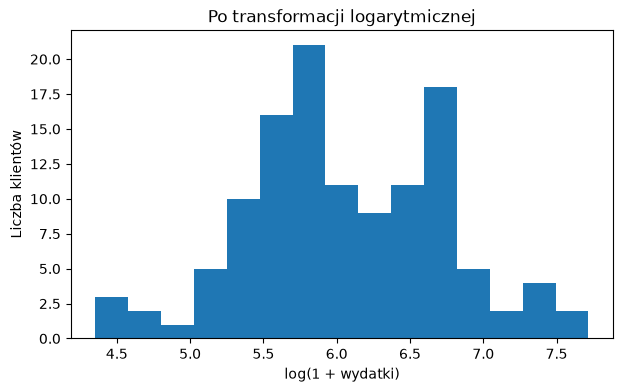

In [12]:
plt.figure(figsize=(7,4))
plt.hist(df['log_wydatki_mies'], bins=15)
plt.xlabel('log(1 + wydatki)'); plt.ylabel('Liczba klientów'); plt.title('Po transformacji logarytmicznej')
plt.show()

In [13]:
_, p_before = shapiro(df['wydatki_mies_pln'])
_, p_after = shapiro(df['log_wydatki_mies'])
print(f'Przed: p={p_before:.5f}')
print(f'Po:    p={p_after:.5f}')

Przed: p=0.00000
Po:    p=0.44621


Transformację dobieramy ze względu na cel analizy i model, a nie wyłącznie po to, aby uzyskać `p>0.05`.

# Część B. Jednorodność wariancji

## 6. Test Levene’a / Browna-Forsythe’a

Sprawdzimy `czas_realizacji_min` w trzech kanałach. H₀: wariancje są równe. H₁: co najmniej jedna wariancja się różni. Użyjemy `center="median"`.

In [14]:
groups = [df.loc[df['kanal']==k,'czas_realizacji_min'] for k in ['WWW','Aplikacja','Sklep']]
for k,g in zip(['WWW','Aplikacja','Sklep'], groups):
    print(k, 'n=',len(g),'średnia=',round(g.mean(),2),'odch.std.=',round(g.std(ddof=1),2))
stat,p = levene(*groups, center='median')
print(f'\nBrown-Forsythe / Levene: stat={stat:.4f}, p={p:.6f}')

WWW n= 46 średnia= 18.11 odch.std.= 1.97
Aplikacja n= 56 średnia= 18.04 odch.std.= 4.43
Sklep n= 18 średnia= 17.76 odch.std.= 5.34

Brown-Forsythe / Levene: stat=14.9107, p=0.000002


# Część C. Zmiana reprezentacji danych

## 7. One-Hot Encoding

`region` jest cechą nominalną — nie ma naturalnego porządku. Kodowanie 1,2,3,4 wprowadziłoby sztuczną kolejność i odległość.

In [15]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded = encoder.fit_transform(df[['region']])
encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(['region']))
encoded_df.head()

,region_Południe,region_Północ,region_Wschód,region_Zachód
0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,1.0
4,0.0,0.0,1.0,0.0


In [16]:
pd.concat([df[['region']].head().reset_index(drop=True), encoded_df.head().reset_index(drop=True)], axis=1)

,region,region_Południe,region_Północ,region_Wschód,region_Zachód
0,Zachód,0.0,0.0,0.0,1.0
1,Wschód,0.0,0.0,1.0,0.0
2,Zachód,0.0,0.0,0.0,1.0
3,Zachód,0.0,0.0,0.0,1.0
4,Wschód,0.0,0.0,1.0,0.0


`handle_unknown="ignore"` pozwala przekształcić nową kategorię bez błędu. Wszystkie kolumny one-hot będą wtedy równe 0.

In [17]:
encoder.transform(pd.DataFrame({'region':['Centrum']}))

array([[0., 0., 0., 0.]])

# Część D. Skalowanie i normalizacja

## 8. Dlaczego skala cech ma znaczenie?

Porównamy odległości dla dwóch cech w różnych jednostkach.

In [18]:
A=np.array([500.,5.]); B=np.array([510.,5.]); C=np.array([510.,10.])
def euclidean(a,b): return np.sqrt(np.sum((a-b)**2))
print('d(A,B)=',round(euclidean(A,B),3))
print('d(A,C)=',round(euclidean(A,C),3))

d(A,B)= 10.0
d(A,C)= 11.18


Bez skalowania cecha o większych liczbach może dominować metrykę. Skalowanie nie oznacza jednak, że wszystkie cechy są równie ważne merytorycznie.

## 9. MinMaxScaler i StandardScaler — fit tylko na treningu

In [19]:
features=['wydatki_mies_pln','wizyty_mies','czas_realizacji_min']
X_train,X_test=train_test_split(df[features], test_size=.25, random_state=7)
minmax=MinMaxScaler(); standard=StandardScaler()
X_train_mm=minmax.fit_transform(X_train); X_test_mm=minmax.transform(X_test)
X_train_std=standard.fit_transform(X_train); X_test_std=standard.transform(X_test)
print('Średnie treningu po StandardScaler:', np.round(X_train_std.mean(axis=0),6))
print('Odch.std. treningu:', np.round(X_train_std.std(axis=0,ddof=0),6))

Średnie treningu po StandardScaler: [-0.  0. -0.]
Odch.std. treningu: [1. 1. 1.]


In [20]:
print('Średnie testu po StandardScaler:', np.round(X_test_std.mean(axis=0),3))

Średnie testu po StandardScaler: [-0.151  0.32  -0.181]


Test nie musi mieć średniej 0, ponieważ parametry standaryzacji pochodzą z treningu.

## 10. Nowa wartość poza zakresem treningowym

Po `MinMaxScaler` nowa wartość może przekroczyć 1, jeśli jest większa niż maksimum treningowe.

In [21]:
new_customer=pd.DataFrame({
    'wydatki_mies_pln':[X_train['wydatki_mies_pln'].max()*1.4],
    'wizyty_mies':[X_train['wizyty_mies'].max()+3],
    'czas_realizacji_min':[X_train['czas_realizacji_min'].max()+5]
})
display(new_customer)
print(np.round(minmax.transform(new_customer),3))

,wydatki_mies_pln,wizyty_mies,czas_realizacji_min
0,3144.988,18,34.14


[[1.414 1.231 1.263]]


## 11. RobustScaler i wartość skrajna

`RobustScaler` opiera się na medianie i IQR. Jest mniej wrażliwy na pojedyncze skrajności niż średnia i odchylenie standardowe, ale nie usuwa odstających obserwacji.

In [22]:
x=np.array([[20.],[21.],[22.],[23.],[24.],[150.]])
ss=StandardScaler(); rs=RobustScaler()
pd.DataFrame({'oryginal':x.ravel(), 'StandardScaler':np.round(ss.fit_transform(x).ravel(),3), 'RobustScaler':np.round(rs.fit_transform(x).ravel(),3)})

,oryginal,StandardScaler,RobustScaler
0,20.0,-0.489,-1.0
1,21.0,-0.468,-0.6
2,22.0,-0.447,-0.2
3,23.0,-0.426,0.2
4,24.0,-0.405,0.6
5,150.0,2.235,51.0


## 12. Normalizer — działa na wierszach

`Normalizer` normalizuje każdy wektor niezależnie. To inny cel niż skalowanie kolumn.

In [23]:
profiles=np.array([[2.,4.,4.],[4.,8.,8.],[5.,1.,2.]])
l2=Normalizer(norm='l2').transform(profiles)
print(np.round(l2,3))
print('Normy L2:', np.round(np.linalg.norm(l2,axis=1),3))

[[0.333 0.667 0.667]
 [0.333 0.667 0.667]
 [0.913 0.183 0.365]]
Normy L2: [1. 1. 1.]


Pierwsze dwa profile mają ten sam kierunek, więc po L2 są identyczne. Informacja o ich pierwotnej długości zostaje utracona.

# Część E. Współliniowość

## 13. Macierz korelacji

In [24]:
corr_cols=['wydatki_mies_pln','wydatki_roczne_pln','wizyty_mies','czas_realizacji_min','satysfakcja']
df[corr_cols].corr().round(3)

,wydatki_mies_pln,wydatki_roczne_pln,wizyty_mies,czas_realizacji_min,satysfakcja
wydatki_mies_pln,1.000,0.998,-0.192,-0.052,-0.011
wydatki_roczne_pln,0.998,1.000,-0.190,-0.062,-0.012
wizyty_mies,-0.192,-0.190,1.000,-0.035,0.000
czas_realizacji_min,-0.052,-0.062,-0.035,1.000,-0.025
satysfakcja,-0.011,-0.012,0.000,-0.025,1.000


Silna korelacja między predyktorami może powodować problemy w modelach liniowych: trudniejszą interpretację indywidualnych wpływów i niestabilność współczynników.

## 14. VIF — Variance Inflation Factor

Dla cechy `X_j`: `VIF = 1/(1-R_j^2)`, gdzie `R_j^2` pochodzi z regresji tej cechy względem pozostałych predyktorów.

In [25]:
def calculate_vif(data):
    rows=[]
    for col in data.columns:
        y=data[col]; X=data.drop(columns=col)
        r2=LinearRegression().fit(X,y).score(X,y)
        vif=np.inf if r2>=1 else 1/(1-r2)
        rows.append([col,r2,vif])
    return pd.DataFrame(rows,columns=['cecha','R2','VIF'])

vif_table=calculate_vif(df[['wydatki_mies_pln','wydatki_roczne_pln','wizyty_mies','czas_realizacji_min','satysfakcja']])
vif_table.sort_values('VIF',ascending=False)

,cecha,R2,VIF
1,wydatki_roczne_pln,0.995127,205.221972
0,wydatki_mies_pln,0.995124,205.085658
2,wizyty_mies,0.039013,1.040597
3,czas_realizacji_min,0.028205,1.029024
4,satysfakcja,0.001226,1.001228


Bardzo wysoki VIF oznacza, że dana cecha jest w dużym stopniu wyjaśniana przez pozostałe. Można rozważyć usunięcie redundantnej cechy, regularyzację albo redukcję wymiaru — zależnie od celu modelu.

# Część F. Zadania do samodzielnego wykonania

Korzystaj z `klienci_sklepu_dydaktyczne.csv`. Nie zmieniaj pliku źródłowego.

## Zadanie 1. Normalność rozkładu

Dla `czas_realizacji_min`:
1. narysuj histogram,
2. wykonaj test Shapiro–Wilka,
3. utwórz Q-Q plot,
4. oceń H₀ na poziomie 0,05,
5. skomentuj wynik również na podstawie wykresu.

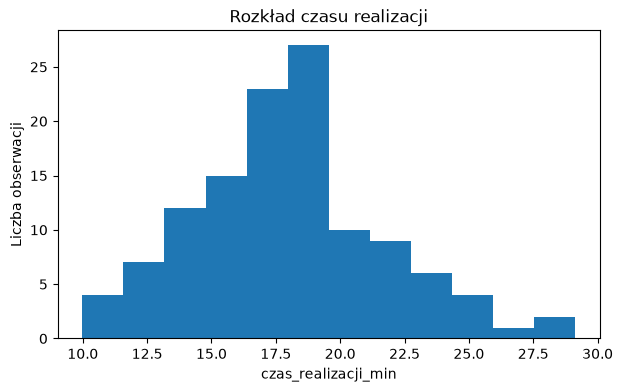

Shapiro-Wilk: stat=0.9843, p=0.1795
Brak podstaw do odrzucenia H0.
Po wykresie widać, że rozkład jest zbliżony do normalnego


In [38]:
# TODO - Zadanie 1

x = df["czas_realizacji_min"]

plt.figure(figsize=(7,4))
plt.hist(x, bins=12)
plt.xlabel('czas_realizacji_min'); plt.ylabel('Liczba obserwacji'); plt.title('Rozkład czasu realizacji')
plt.show()

stat, p = shapiro(x)
print(f'Shapiro-Wilk: stat={stat:.4f}, p={p:.4f}')
print('Odrzucamy H0.' if p < 0.05 else 'Brak podstaw do odrzucenia H0.')
print("Po wykresie widać, że rozkład jest zbliżony do normalnego")

## Zadanie 2. Transformacja zmiennej skośnej

Dla `wydatki_roczne_pln`:
1. oblicz skośność,
2. zastosuj `np.log1p`,
3. ponownie oblicz skośność,
4. porównaj histogramy,
5. oceń, czy transformacja zmniejszyła asymetrię.

Skośność przed: 1.934
Skośność po: -0.489


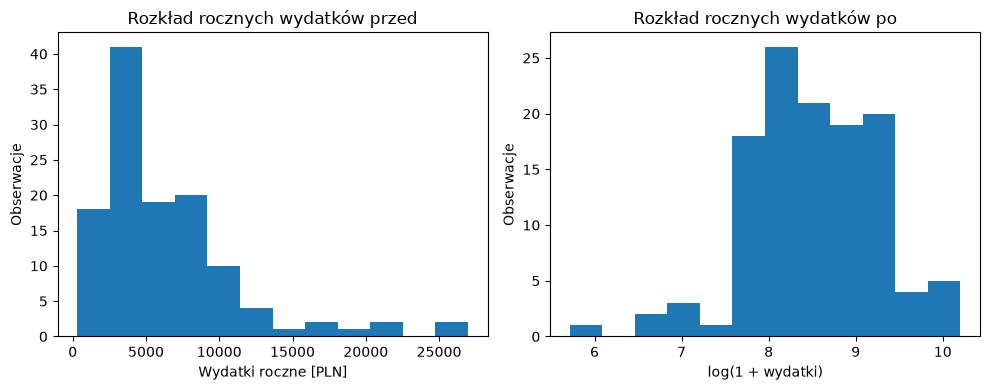

Transformacja zmniejszyła skośność


In [52]:
# TODO - Zadanie 2
yearly_spending = df["wydatki_roczne_pln"]
print(f"Skośność przed: {round(yearly_spending.skew(), 3)}")

df["log_wydatki_roczne"] = np.log1p(yearly_spending)
print(f"Skośność po: {round(df["log_wydatki_roczne"].skew(), 3)}")

figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.hist(yearly_spending, 12)
ax1.set_title("Rozkład rocznych wydatków przed")
ax1.set_xlabel("Wydatki roczne [PLN]")
ax1.set_ylabel("Obserwacje")

ax2.hist(df["log_wydatki_roczne"], 12)
ax2.set_title("Rozkład rocznych wydatków po")
ax2.set_xlabel("log(1 + wydatki)")
ax2.set_ylabel("Obserwacje")
plt.tight_layout()
plt.show()

print("Transformacja zmniejszyła skośność")

## Zadanie 3. Jednorodność wariancji

Sprawdź wariancję `czas_realizacji_min` pomiędzy regionami Północ, Południe, Wschód, Zachód. Użyj `levene(..., center="median")`. Zapisz H₀/H₁ i zinterpretuj `p`.

In [53]:
# TODO - Zadanie 3

groups = [df.loc[df['region']==k,'czas_realizacji_min'] for k in ['Północ','Południe','Wschód', 'Zachód']]
for k,g in zip(['Północ','Południe','Wschód', 'Zachód'], groups):
    print(k, 'n=',len(g),'średnia=',round(g.mean(),2),'odch.std.=',round(g.std(ddof=1),2))
stat,p = levene(*groups, center='median')
print(f'\nBrown-Forsythe / Levene: stat={stat:.4f}, p={p:.6f}')

Północ n= 32 średnia= 17.63 odch.std.= 3.09
Południe n= 33 średnia= 17.46 odch.std.= 3.7
Wschód n= 29 średnia= 18.96 odch.std.= 4.37
Zachód n= 26 średnia= 18.17 odch.std.= 4.15

Brown-Forsythe / Levene: stat=0.6301, p=0.597024


## Zadanie 4. One-Hot Encoding

Zakoduj `kanal`. Wyświetl nazwy nowych kolumn i 5 pierwszych rekordów. Następnie przekształć nową kategorię `Telefon` i wyjaśnij wynik.

In [ ]:
# TODO - Zadanie 4

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded = encoder.fit_transform(df[['kanal']])
encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(['kanal']))
encoded_df.head()

encoder.transform(pd.DataFrame({"kanal": ["Telefon"]}))

,kanal_Aplikacja,kanal_Sklep,kanal_WWW
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0


## Zadanie 5. Porównanie skalowania

Dla `wydatki_mies_pln`, `wizyty_mies`, `czas_realizacji_min` zastosuj `MinMaxScaler`, `StandardScaler` i `RobustScaler`. Pokaż 5 pierwszych wierszy i krótko porównaj interpretację wyników.

In [ ]:
# TODO - Zadanie 5

features = ["wydatki_mies_pln", "wizyty_mies", "czas_realizacji_min"]
minmax = MinMaxScaler(); standard = StandardScaler(); robust = RobustScaler()
X_train, X_test = train_test_split(
    df[features],
    train_size=0.25,
    random_state=42
)

X_train_mm = minmax.fit_transform(X_train); X_test_mm = minmax.transform(X_test)
X_train_st = standard.fit_transform(X_train); X_test_st = standard.transform(X_test)
X_train_rb = robust.fit_transform(X_train); X_test_rb = robust.transform(X_test)



array([[ 0.33536843,  0.66666667,  0.55555556],
       [ 0.30959459,  0.77777778,  0.36718175],
       [ 0.09269013,  0.22222222,  0.10596026],
       [ 0.45402269,  0.88888889,  0.39440765],
       [ 0.12219811,  0.88888889,  0.33112583],
       [ 0.13669235,  0.55555556,  0.56806475],
       [ 0.11977554,  0.33333333,  0.50331126],
       [ 0.06964232,  1.        ,  0.15011038],
       [ 0.06870622,  1.        ,  0.76821192],
       [ 0.68015451,  0.44444444, -0.01398087],
       [ 0.09612081,  0.77777778,  0.46504783],
       [ 0.29274465,  0.77777778,  0.00956586],
       [ 1.09372396,  0.22222222,  0.29801325],
       [ 0.16357717,  0.22222222,  1.25091979],
       [ 0.32035469,  0.77777778,  0.75349522],
       [-0.01640246,  0.77777778,  0.53863135],
       [ 0.23995227,  0.66666667,  0.74760854],
       [ 0.09133226,  0.44444444,  0.31125828],
       [ 0.39879232,  0.22222222,  0.44738779],
       [ 0.29268293,  1.        , -0.09933775],
       [ 0.84384998,  0.77777778,  1.122

## Zadanie 6. Skalowanie bez wycieku informacji

Podziel dane 80/20 (`random_state=21`). Dla `StandardScaler`: `fit` tylko na treningu, transform treningu i testu, średnia i odchylenie treningu po transformacji, średnia testu. Wyjaśnij, dlaczego test nie musi mieć średniej 0.

In [ ]:
# TODO - Zadanie 6

features = ["wydatki_mies_pln", "wizyty_mies", "czas_realizacji_min"]
standard = StandardScaler();
X_train, X_test = train_test_split(
    df[features],
    train_size=0.20,
    random_state=21
)

X_train_st = standard.fit_transform(X_train); X_test_st = standard.transform(X_test)

print('Średnie treningu po StandardScaler:', np.round(X_train_st.mean(axis=0),6))
print('Odch.std. treningu:', np.round(X_train_st.std(axis=0,ddof=0),6))

print('Średnie testu po StandardScaler:', np.round(X_test_std.mean(axis=0),6))
print('Odch.std. testu:', np.round(X_test_std.std(axis=0,ddof=0),6))

Średnie treningu po StandardScaler: [-0.  0.  0.]
Odch.std. treningu: [1. 1. 1.]
Średnie testu po StandardScaler: [-0.151011  0.319694 -0.181387]
Odch.std. testu: [0.842348 1.180107 0.980732]


## Zadanie 7. Normalizacja L1 i L2

Dla pierwszych 5 klientów zbuduj wektory `[wizyty_mies, liczba_produktow, satysfakcja]`. Wykonaj L1 i L2. Sprawdź sumę wartości bezwzględnych po L1 (parametr `ord=1` w funkcji `np.linalg.norm`) oraz długość euklidesową po L2.

In [62]:
# TODO - Zadanie 7
profiles=np.array([df["wizyty_mies"],df["liczba_produktow"],df["satysfakcja"]])

l1=Normalizer(norm='l1').transform(profiles)
print(np.round(l1,3))
print('Normy L1:', np.round(np.linalg.norm(l1,axis=1),3))

l2=Normalizer(norm='l2').transform(profiles)
print(np.round(l2,3))
print('Normy L2:', np.round(np.linalg.norm(l2,axis=1),3))

[[0.007 0.006 0.011 0.008 0.005 0.013 0.006 0.005 0.008 0.014 0.011 0.005
  0.01  0.007 0.006 0.007 0.011 0.003 0.01  0.004 0.006 0.007 0.009 0.008
  0.009 0.003 0.011 0.005 0.011 0.006 0.008 0.014 0.009 0.01  0.011 0.011
  0.005 0.009 0.006 0.011 0.011 0.013 0.007 0.014 0.009 0.004 0.011 0.01
  0.007 0.008 0.011 0.009 0.009 0.011 0.011 0.011 0.011 0.01  0.009 0.009
  0.003 0.008 0.01  0.008 0.008 0.01  0.015 0.008 0.011 0.006 0.01  0.005
  0.006 0.006 0.009 0.01  0.011 0.009 0.006 0.007 0.007 0.006 0.011 0.011
  0.007 0.006 0.006 0.008 0.005 0.01  0.01  0.01  0.009 0.011 0.005 0.002
  0.01  0.007 0.009 0.005 0.006 0.008 0.008 0.008 0.011 0.007 0.01  0.007
  0.009 0.009 0.015 0.013 0.011 0.007 0.005 0.009 0.01  0.007 0.01  0.011]
 [0.005 0.012 0.007 0.009 0.005 0.005 0.021 0.014 0.007 0.005 0.005 0.028
  0.007 0.012 0.009 0.007 0.002 0.007 0.005 0.005 0.007 0.007 0.009 0.005
  0.014 0.007 0.002 0.012 0.012 0.021 0.005 0.005 0.005 0.002 0.002 0.012
  0.005 0.005 0.009 0.005 0.005 0.007 

## Zadanie 8. Współliniowość

Dla `wydatki_mies_pln`, `wydatki_roczne_pln`, `staz_mies`, `wizyty_mies`, `satysfakcja`: policz korelacje i VIF, wskaż problematyczne cechy i zaproponuj jedno działanie przed budową modelu regresji.

In [67]:
# TODO - Zadanie 8
corr_cols=['wydatki_mies_pln','wydatki_roczne_pln','staz_mies','wizyty_mies','satysfakcja']
display(df[corr_cols].corr().round(3))

vif_table=calculate_vif(df[['wydatki_mies_pln','wydatki_roczne_pln','staz_mies','wizyty_mies','satysfakcja']])
display(vif_table.sort_values('VIF',ascending=False))

,wydatki_mies_pln,wydatki_roczne_pln,staz_mies,wizyty_mies,satysfakcja
wydatki_mies_pln,1.000,0.998,0.045,-0.192,-0.011
wydatki_roczne_pln,0.998,1.000,0.047,-0.190,-0.012
staz_mies,0.045,0.047,1.000,0.018,-0.015
wizyty_mies,-0.192,-0.190,0.018,1.000,0.000
satysfakcja,-0.011,-0.012,-0.015,0.000,1.000


,cecha,R2,VIF
0,wydatki_mies_pln,0.995021,200.835695
1,wydatki_roczne_pln,0.995018,200.730726
3,wizyty_mies,0.037859,1.039348
2,staz_mies,0.003924,1.003939
4,satysfakcja,0.000596,1.000596


## Zadanie dodatkowe. Wpływ obserwacji skrajnej

Do kopii `wydatki_mies_pln` dopisz wartość `50000`. Porównaj parametry `StandardScaler` i `RobustScaler` przed i po dodaniu tej wartości. Która metoda jest bardziej odporna i dlaczego?

In [34]:
# TODO - Zadanie dodatkowe

# Literatura

- **Jiawei Han, Micheline Kamber, Jian Pei**, *Data Mining: Concepts and Techniques*, 3rd ed., Morgan Kaufmann, 2011.
- **Charu C. Aggarwal**, *Data Mining: The Textbook*, Springer, 2015.
- **Miroslav Kubat**, *An Introduction to Machine Learning*, 2nd ed., Springer, 2017.
- **Steven S. Skiena**, *The Data Science Design Manual*, Springer, 2017.
- **Charu C. Aggarwal**, *Neural Networks and Deep Learning: A Textbook*, Springer, 2018.
- **Piotr Wróblewski**, *Machine Learning i Natural Language Processing w programowaniu. Podręcznik z ćwiczeniami w Pythonie*, Helion S.A., 2024.